## Figure 7: SEI contributions of BLI-GAT-SEI model
Predicts Rf and per-fragment contributions with the BLI segment-sum-contribution model for the 11,486 distinct molecules in `./data/molecules.csv` at three hexane : ethyl acetate ratios (10:1, 4:1, 1:1), then plots the contribution distributions of 12 functional groups. No files are written.

In [1]:
import contextlib
import io
import os
# os.environ["TQDM_DISABLE"] = "1"  # silence per-batch progress bars

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import D4CMPP_TLC
import SSC

In [2]:
INPUT_CSV = "./data/molecules.csv"
MODEL_NAME = "BLI_segment_sum_contribution"
MODEL_DIR = os.path.join(os.path.abspath(''), "Trained_models")  # DTLC/SEI_models/Trained_models
MODEL_PATH = os.path.join(MODEL_DIR, MODEL_NAME)
BATCH_SIZE = 64

# ratio1 (hexane mole fraction) -> hexane : ethyl acetate volume ratio
RATIO_LABELS = {0.882244: '10:1', 0.749803: '4:1', 0.428314: '1:1'}
RATIO_COLORS = {'10:1': 'blue', '4:1': 'green', '1:1': 'red'}

# tanh-normalized contribution in [-1, 1]
CONTRIB_COL = "normalized_subgroup_contribution"

# (fragment SMILES, panel title)
GROUPS = [
    ('*O', 'Hydroxyl'), ('*N', 'Amino'), ('*C#N', 'Nitrile'),
    ('*C(=O)O', 'Carboxyl'), ('*C=O', 'Aldehyde'), ('*[N+](=O)[O-]', 'Nitro'),
    ('c1ccccc1', 'Benzene'), ('*C', 'Methyl'), ('*CCC', 'n-Propyl'),
    ('C1CCCCC1', 'Cyclohexane'), ('*CC', 'Ethyl'), ('*C(C)C', 'Isopropyl'),
]

In [3]:
BLI_segment = SSC.src.SSCAnalyzer.SSCAnalyzer_v1p3(MODEL_PATH)

sk_scaler = BLI_segment.scaler.scaler  # sklearn StandardScaler fitted on the training Rf values
RF_MEAN = float(sk_scaler.mean_[0])
RF_STD = float(sk_scaler.scale_[0])
print(f"Rf scaler: mean={RF_MEAN:.6f}, std={RF_STD:.6f}")

founded model: /home/ainshin/a_shared/DTLC/SEI_models/Trained_models/BLI_segment_sum_contribution
Device: cuda
#params: 184707
Loading params from /home/ainshin/a_shared/DTLC/SEI_models/Trained_models/BLI_segment_sum_contribution/final.pth


/home/ainshin/miniconda3/envs/tlc_final/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Sculptor Index: (6, 2, 0)
Rf scaler: mean=0.445887, std=0.232983


In [4]:
df = pd.read_csv(INPUT_CSV, encoding="utf-8-sig")
df = df.reset_index(drop=True)
df["ratio_label"] = df["ratio1"].round(6).map(RATIO_LABELS)
assert df["ratio_label"].notna().all(), "unexpected ratio1 value"
print(df.shape)
print(df["ratio_label"].value_counts())
df.head()

(34458, 6)
ratio_label
10:1    11486
4:1     11486
1:1     11486
Name: count, dtype: int64


,Smiles,eluent1_smiles,eluent2_smiles,ratio1,ratio2,ratio_label
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,1:1
3,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.882244,0.117756,10:1
4,BrC/C=C\COC1CCCCO1,CCCCCC,CCOC(C)=O,0.749803,0.250197,4:1


## Prediction
`get_score` is called per batch; the per-fragment contributions are split per molecule by `subgroup_size` and checked against `get_fragment()`.

In [5]:
def quiet(func, **kwargs):
    """Call func while hiding its per-call "'i2i' edge type not found" messages (harmless for these models)."""
    with contextlib.redirect_stdout(io.StringIO()):
        return func(**kwargs)


def score_batch(analyzer, batch):
    score = quiet(analyzer.get_score,
        Smiles=list(batch["Smiles"]),
        eluent1_smiles=list(batch["eluent1_smiles"]),
        eluent2_smiles=list(batch["eluent2_smiles"]),
        ratio1=[float(x) for x in batch["ratio1"]],
        ratio2=[float(x) for x in batch["ratio2"]],
    )
    y = np.asarray(score["y"], dtype=float).reshape(-1)
    contrib = np.asarray(score["subgroup_contributions"], dtype=float).reshape(-1)
    sizes = np.asarray(score["subgroup_size"]).reshape(-1).astype(int)

    if len(y) != len(batch) or len(sizes) != len(batch):
        raise ValueError(f"Output count ({len(y)}) != input rows ({len(batch)}). Check for invalid SMILES.")
    if sizes.sum() != len(contrib):
        raise ValueError("Sum of subgroup_size != length of subgroup_contributions.")

    offsets = np.concatenate([[0], np.cumsum(sizes)])
    return [(y[i], contrib[offsets[i]:offsets[i + 1]]) for i in range(len(batch))]


frag_cache = {}  
mol_rows = []
frag_rows = []

for start in range(0, len(df), BATCH_SIZE):
    batch = df.iloc[start:start + BATCH_SIZE]
    results = score_batch(BLI_segment, batch)

    for (row_idx, row), (y_scaled, contribs) in zip(batch.iterrows(), results):
        smi = row["Smiles"]
        if smi not in frag_cache:
            frag_cache[smi] = BLI_segment.get_fragment(smi)
        fragments = frag_cache[smi]
        if len(fragments) != len(contribs):
            raise ValueError(f"row {row_idx}: #fragments ({len(fragments)}) != #contributions ({len(contribs)}) | {smi}")

        mol_rows.append({"row_id": row_idx, "Rf_pred": RF_MEAN + RF_STD * y_scaled, "y_scaled": y_scaled})

        for frag, c in zip(fragments, contribs):
            frag_rows.append({
                "row_id": row_idx,
                "ratio_label": row["ratio_label"],
                "frag_smiles": frag.smiles,
                "contribution": c,                               # model output (standardized Rf space)
                "normalized_subgroup_contribution": np.tanh(c),  # [-1, 1]
            })

mol_df = pd.DataFrame(mol_rows)
frag_df = pd.DataFrame(frag_rows)
print(mol_df.shape, frag_df.shape)

Generating eluent2_smiles graphs: 100%|███████| 26/26 [00:00<00:00, 171.73it/s]


(34458, 3) (201450, 5)


## Figure 7

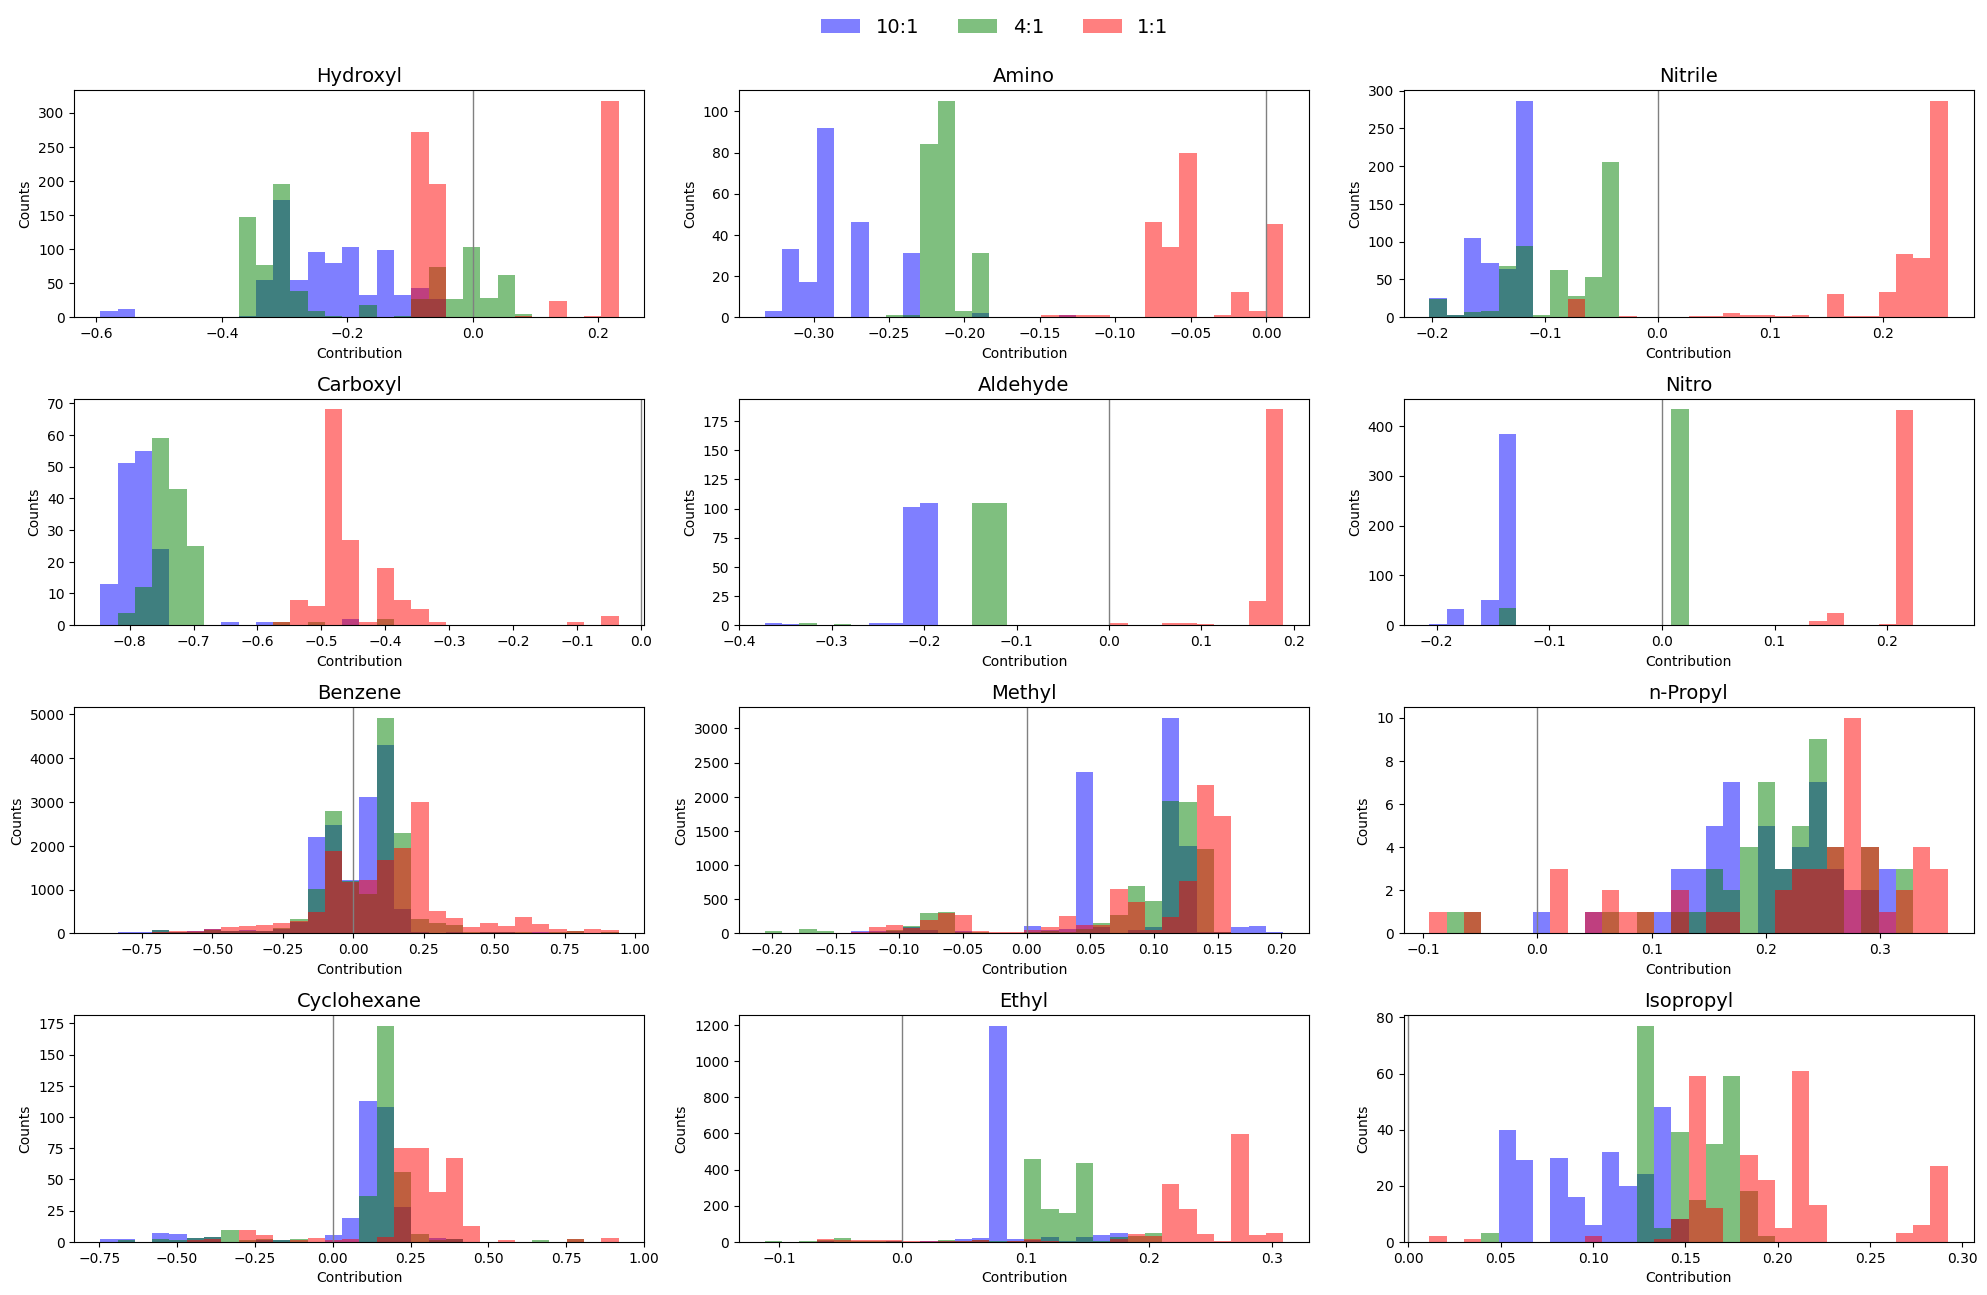

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(20, 13))

for ax, (frag, title) in zip(axes.flat, GROUPS):
    sub = frag_df[frag_df["frag_smiles"] == frag]
    values = [sub.loc[sub["ratio_label"] == lab, CONTRIB_COL].values for lab in RATIO_COLORS]

    bins = np.histogram_bin_edges(np.concatenate(values), bins=30)
    for lab, v in zip(RATIO_COLORS, values):
        ax.hist(v, bins=bins, color=RATIO_COLORS[lab], alpha=0.5, label=lab)

    ax.axvline(0, color='gray', linestyle='-', linewidth=1)   # x = 0 reference line

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Contribution')
    ax.set_ylabel('Counts')

# one shared legend for all panels
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper center', ncol=len(RATIO_COLORS), fontsize=14,
           frameon=False, bbox_to_anchor=(0.5, 1.0))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()